# Mini Project 1: Probability, Bayes, and Discrete Random Variables

In [112]:
# Put imports here
import numpy as np
import mp1lib as ml
import scipy as sp
from scipy.stats import binom
import matplotlib as mp
import matplotlib.pyplot as plt
import jupyter as jp
import math as mat

SEED = 733634
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8 = rng.spawn(8)

## Step 1: The sample space and the axioms

C:\Users\marie\AppData\Local\Temp\ipykernel_39332\1039700290.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(xticklabels = [f"{i:04b} " for i in range(16)],


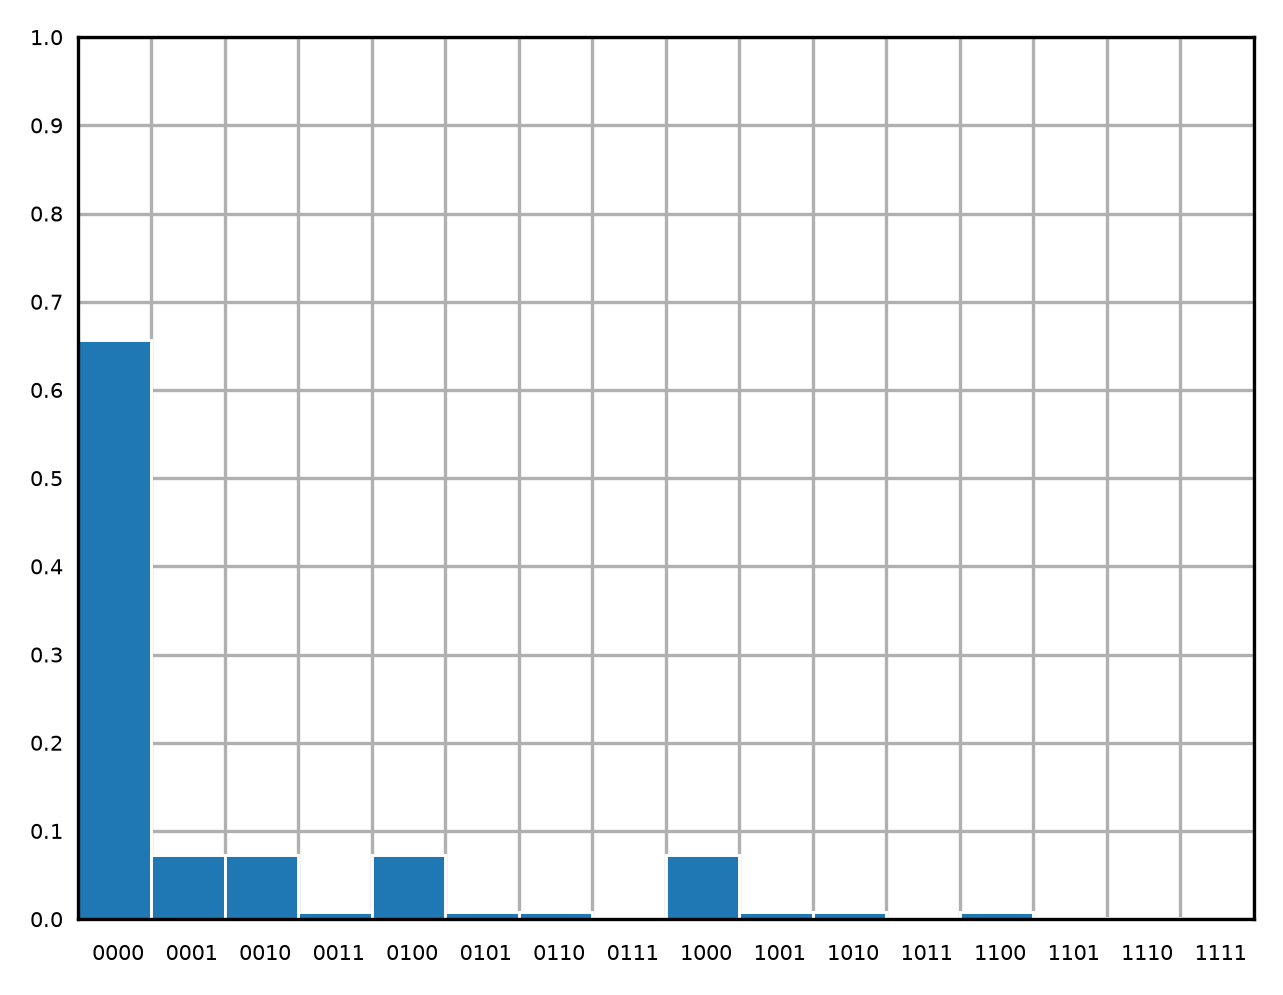

pattern 0000: p = 0.6561
pattern 0001: p = 0.0729
pattern 0010: p = 0.0729
pattern 0011: p = 0.0081
pattern 0100: p = 0.0729
pattern 0101: p = 0.0081
pattern 0110: p = 0.0081
pattern 0111: p = 0.0009
pattern 1000: p = 0.0729
pattern 1001: p = 0.0081
pattern 1010: p = 0.0081
pattern 1011: p = 0.0009
pattern 1100: p = 0.0081
pattern 1101: p = 0.0009
pattern 1110: p = 0.0009
pattern 1111: p = 0.0001

sum = 1.0000


In [113]:
# Question 1

n_bits, p = 4, 0.1
pattern = np.zeros(16) # pattern[#] = binary packet value with err = 1 and ~err=0

def err_pattern(n_bits, p, n_errs):
    return (1 - p) ** (n_bits - n_errs) * p ** n_errs

for i in range(16):
    pattern[i] = err_pattern(n_bits, p, i.bit_count())


plt.style.use('_mpl-gallery')

# make data:
x = 0.5 + np.arange(16)
y = pattern

# plot
fig, ax = plt.subplots(figsize=(4, 3), dpi=300)

ax.bar(x, y, width=1, edgecolor="white", linewidth=0.7)

ax.set(xticklabels = [f"{i:04b} " for i in range(16)],
       xlim = (0, 16), xticks = np.arange(1,17),
       ylim = (0, 1), yticks = np.arange(0, 1.05, 0.1))

ax.tick_params(axis = 'x', pad = 6, labelsize = 5)
ax.tick_params(axis = 'y', labelsize = 5)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

plt.show()

for i in range(16):
    print(f"pattern {i:04b}: p = {pattern[i]:.4f}")
print(f"\nsum = {np.sum(pattern):.4f}")

In [114]:
# Question 2

P_A = 1 - sp.stats.binom.pmf(0, 2, p)
P_B = sp.stats.binom.pmf(2, n_bits, p)
P_C = p

print("Theoretical:")
print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(B) = {P_C:.4f}")

Theoretical:
P(A) = 0.1900
P(B) = 0.0486
P(B) = 0.1000


In [115]:
# Question 3

N = 10 ** 6

P_A_sim = np.mean(ml.packet_errors(N, 2, p, rng_1) > 0)
P_B_sim = np.mean(ml.packet_errors(N, n_bits, p, rng_1) == 2)
P_C_sim = np.mean(ml.packet_errors(N, 1, p, rng_1))

print("Simulation:")
print(f"P(A) \u2248 {P_A_sim:.4f}")
print(f"P(B) \u2248 {P_B_sim:.4f}")
print(f"P(C) \u2248 {P_C_sim:.4f}")

Simulation:
P(A) ≈ 0.1899
P(B) ≈ 0.0480
P(C) ≈ 0.0997


In [116]:
# Question 4

P_AB = P_B - P_B / sp.special.comb(4, 2)
P_BC = p * sp.stats.binom.pmf(1, n_bits-1, p)
P_CA = P_C * P_A
P_ABC = sp.stats.binom.pmf(1, 2, p) * (1-p) * p

bits_in = np.zeros((N,n_bits), int)
bits_out = ml.bsc(bits_in, p, rng_1)
A_arr_err = np.sum(bits_out[:, :2], axis = 1) > 0
B_arr_err = np.sum(bits_out, axis = 1) == 2
C_arr_err = bits_out[:, 3]

P_AB_sim = np.mean(A_arr_err & B_arr_err)
P_BC_sim = np.mean(B_arr_err & C_arr_err)
P_CA_sim = np.mean(C_arr_err & A_arr_err)
P_ABC_sim = np.mean(A_arr_err & B_arr_err & C_arr_err)

print("Theoretical:")
print(f"P(A \u2229 B) = {P_AB:.4f}")
print(f"P(B \u2229 C) = {P_BC:.4f}")
print(f"P(C \u2229 A) = {P_CA:.4f}")
print(f"P(A \u2229 B \u2229 C) = {P_ABC:.4f}\n")

print("Simulation:")
print(f"P(A \u2229 B) \u2248 {P_AB_sim:.4f}")
print(f"P(B \u2229 C) \u2248 {P_BC_sim:.4f}")
print(f"P(C \u2229 A) \u2248 {P_CA_sim:.4f}")
print(f"P(A \u2229 B \u2229 C) \u2248 {P_ABC_sim:.4f}")

Theoretical:
P(A ∩ B) = 0.0405
P(B ∩ C) = 0.0243
P(C ∩ A) = 0.0190
P(A ∩ B ∩ C) = 0.0162

Simulation:
P(A ∩ B) ≈ 0.0405
P(B ∩ C) ≈ 0.0241
P(C ∩ A) ≈ 0.0190
P(A ∩ B ∩ C) ≈ 0.0162


### Inclusion-Exclusion Formulas

$P(A \cup B) = P(A) + P(B) - P(A \cap B)$

$P(A \cup B \cup C) = P(A) + P(B) + P(C) - P(A \cap B) - P(B \cap C) - P(C \cap A) + P(A \cap B \cap C)$

In [117]:
# Question 5

P_ABCU = 1 - sp.stats.binom.pmf(0, 3, p)
P_ABCU_IE = P_A + P_B + P_C - P_AB - P_BC - P_CA + P_ABC

P_ABCU_sim = np.mean(A_arr_err | B_arr_err | C_arr_err)
P_ABCU_sim_IE = P_A_sim + P_B_sim + P_C_sim - P_AB_sim - P_BC_sim - P_CA_sim + P_ABC_sim

print("Theoretical:")
print(f"w/o IE formula: P(A \u222A B \u222A C) = {P_ABCU:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) = {P_ABCU_IE:.4f}\n")

print("Simulation:")
print(f"w/o IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim_IE:.4f}")

Theoretical:
w/o IE formula: P(A ∪ B ∪ C) = 0.2710
w/  IE formula: P(A ∪ B ∪ C) = 0.2710

Simulation:
w/o IE formula: P(A ∪ B ∪ C) ≈ 0.2712
w/  IE formula: P(A ∪ B ∪ C) ≈ 0.2703


In [118]:
# Question 6

results = [
    (P_A, P_A_sim, "Event A"),
    (P_B, P_B_sim, "Event B"),
    (P_C, P_C_sim, "Event C"),
    (P_AB, P_AB_sim, "Intersect AB"),
    (P_BC, P_BC_sim, "Intersect BC"),
    (P_CA, P_CA_sim, "Intersect CA"),
    (P_ABC, P_ABC_sim, "Intersect ABC"),
    (P_ABCU, P_ABCU_sim, "Union ABC"),
    (P_ABCU_IE, P_ABCU_sim_IE, "Union ABC IE")
]

print(f"{'Event':<16} | {'Simulated':<11} | {'Theoretical':<11} | {'Difference':<11} | {'Std. Error':<11} | <3SE")
print("-" * 80)

for p_theory, p_sim, event in results:
    SE = np.sqrt((p_theory * (1 - p_theory)) / N)
    thresh = 3 * SE
    diff = np.abs(p_sim - p_theory)
    test = diff <= thresh
    
    print(f"{event:<16} | {p_sim:<11.6f} | {p_theory:<11.6f} | {diff:<11.6f} | {SE:<11.6f} | {test}")
    
    assert test, f"{event} variation exceeds standard error parameters."

print("\nAll simulations estimate within 3 standard errors.")


Event            | Simulated   | Theoretical | Difference  | Std. Error  | <3SE
--------------------------------------------------------------------------------
Event A          | 0.189858    | 0.190000    | 0.000142    | 0.000392    | True
Event B          | 0.048042    | 0.048600    | 0.000558    | 0.000215    | True
Event C          | 0.099731    | 0.100000    | 0.000269    | 0.000300    | True
Intersect AB     | 0.040477    | 0.040500    | 0.000023    | 0.000197    | True
Intersect BC     | 0.024092    | 0.024300    | 0.000208    | 0.000154    | True
Intersect CA     | 0.018981    | 0.019000    | 0.000019    | 0.000137    | True
Intersect ABC    | 0.016183    | 0.016200    | 0.000017    | 0.000126    | True
Union ABC        | 0.271215    | 0.271000    | 0.000215    | 0.000444    | True
Union ABC IE     | 0.270264    | 0.271000    | 0.000736    | 0.000444    | True

All simulations estimate within 3 standard errors.


## Step 2: Conditional probability and Bayes

### Question 1.

$P(F|err) = 0.95$

$P(F|err^c) = 0.02$

$P(err) = p$

$P(err^c) = 1-p$

$P(F) = P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)$

$P(err|F) = \frac{P(F|err)P(err)}{P(F)}$

In [119]:
# Question 2: Evaluate the posterior at p = 0.1, p = 0.01, and p = 0.001.

prob_F_err = 0.95
prob_F_errc = 0.02

def posterior(F_err, F_errc, p):
    F = (F_err * p) + (F_errc * (1 - p))
    return (F_err * p) / F

print (f"at p = 0.100: {posterior(prob_F_err, prob_F_errc, 0.1):.3f}")
print (f"at p = 0.010: {posterior(prob_F_err, prob_F_errc, 0.01):.3f}")
print (f"at p = 0.001: {posterior(prob_F_err, prob_F_errc, 0.001):.4f}")

at p = 0.100: 0.841
at p = 0.010: 0.324
at p = 0.001: 0.0454


Text(0, 0.5, 'Posterior')

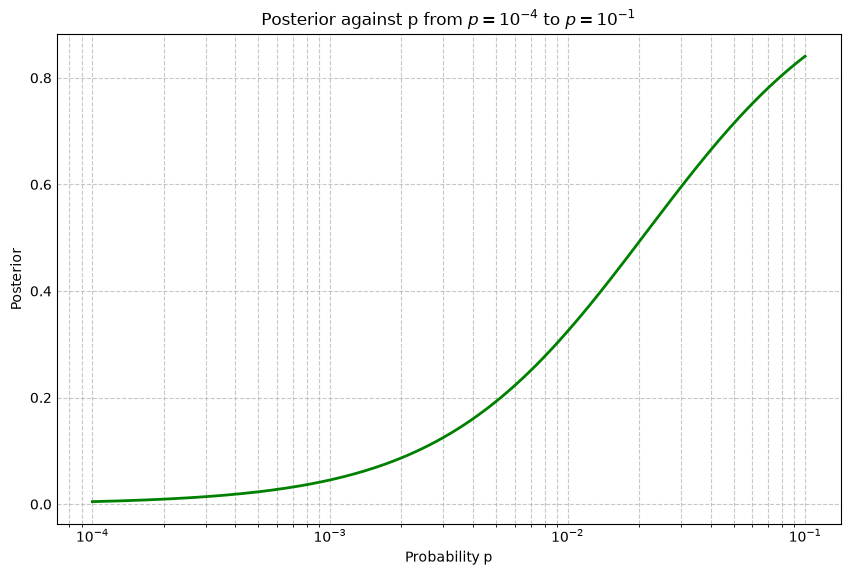

In [120]:
# Question 3: Plot the posterior against p for p from 10^-4 to 10^-1, log spaced, 200 points.

x = np.logspace(-4, -1, 200, True, 10)
y = posterior(prob_F_err, prob_F_errc, x)

plt.figure(figsize = (8, 5))
plt.plot(x, y, label = (r'Posterior against p'), color = 'green', linewidth = 2)
plt.xscale('log')
plt.grid(True, which = 'both', linestyle = '--', alpha = 0.7)
plt.title(r'Posterior against p from $p=10^{-4}$ to $p=10^{-1}$')
plt.xlabel('Probability p')
plt.ylabel('Posterior')

### Question 4: Solve analytically for the p at which the posterior equals 0.5. 

$P(err|F) = \frac{P(F|err)P(err)}{P(F)}$

$P(F) = P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)$

$0.5 = \frac{P(F|err)P(err)}{P(F|err) \cdot P(err) + P(F|err^c) \cdot P(err^c)}$

$P(F|err) \cdot P(err) + P(F|err^c) \cdot (1-P(err)) = 2P(F|err)P(err)$

$P(err)(P(F|err) - P(F|err^c) - 2P(F|err)) = -P(F|err^c)$

$P(err) = \frac{-P(F|err^c)}{P(F|err) - P(F|err^c) - 2P(F|err)}$

$P(err) = \frac{P(F|err^c)}{(P(F|err) + P(F|err^c))}$

At which posterior equals 0.5, p = 0.0206


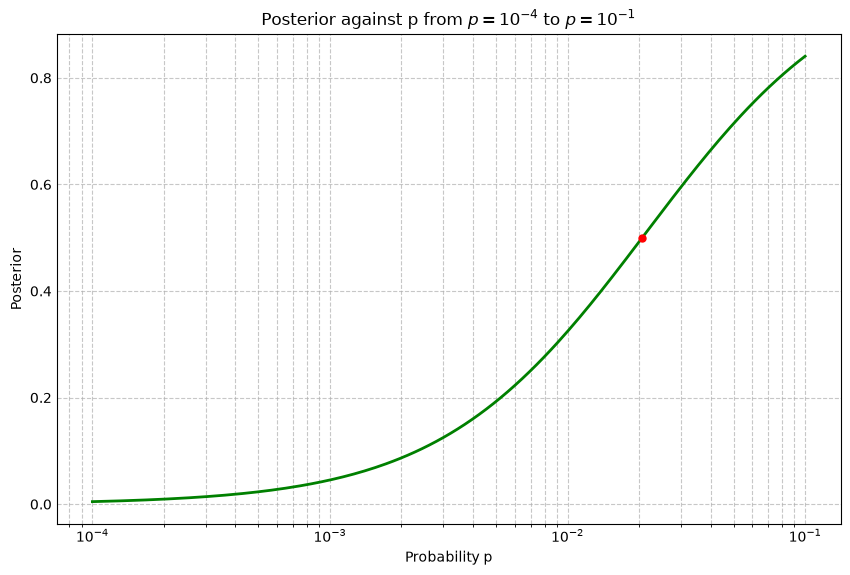

In [121]:
# Report it to three significant figures and mark it on the plot.

x_pdot5 = prob_F_errc / (prob_F_errc + prob_F_err)
print (f"At which posterior equals 0.5, p = {x_pdot5:.3g}")

plt.figure(figsize = (8, 5))
plt.plot(x, y, label = (r'Posterior against p'), color = 'green', linewidth = 2)
plt.xscale('log')
plt.grid(True, which = 'both', linestyle = '--', alpha = 0.7)
plt.title(r'Posterior against p from $p=10^{-4}$ to $p=10^{-1}$')
plt.xlabel('Probability p')
plt.ylabel('Posterior')
plt.plot(x_pdot5, 0.5, 'o', color = 'red', markersize = 5)

In [122]:
# Question 5: Verify that value by Monte Carlo

N_bits = 10**7
p = 0.0206

err = ml.packet_errors(N_bits, 1, p, rng_2)
p_flag = np.where(err, 0.95, 0.02) # defined the conditional probability
flag = rng_2.random(N_bits) < p_flag # implementing the flag circuit

flag_true = np.sum((flag == 1) & (err == 1)) # flag correctly identified error
print (f"Correctly flagged errors:          flag_true = {flag_true}")
flag_tot = np.sum(flag) # total flags on pkt
print (f"Total Flags on pkt:                flag_tot = {flag_tot}")
post = flag_true / flag_tot

print (f"Simulation w/ p = 0.0206:          posterior = {post}")
print (f"Sanity check:                      flag_tot / N_bits = {flag_tot / N_bits}")
print (f"Standard error:                    SE = {np.sqrt((post * (1 - post)) / flag_tot)}")


Correctly flagged errors:          flag_true = 194800
Total Flags on pkt:                flag_tot = 390590
Simulation w/ p = 0.0206:          posterior = 0.49873268644870583
Sanity check:                      flag_tot / N_bits = 0.039059
Standard error:                    SE = 0.000800033272555549


### Question 6:

When a packet is sent with 95% accuracy, it means almost nothing to the error detection circuit, with flag accuracies of 32.4% in a packet with 1% error probability and 4.54% at 0.1% error probability. As the circuit becomes more accurate, the probability of the circuit flagging false-positives becomes higher, and the overall probability of the flags detecting true-positives drops significantly. This creates a scenario where chances of the flags correctly detecting errors become less as the sample size of errors that need to be flagged decrease.

## Step 3: Independence

In [123]:
# call rng_3

## Step 4: Bernoulli trials and the Binomial

### Question 1: 
Binomial by definition means that each trial of the experiment only has two outcomes. Due to the packet being comprised of bits, meaning the value of each bit is 1 or 0, it would mean that the number of errors would have to be a discrete value of error or no error.

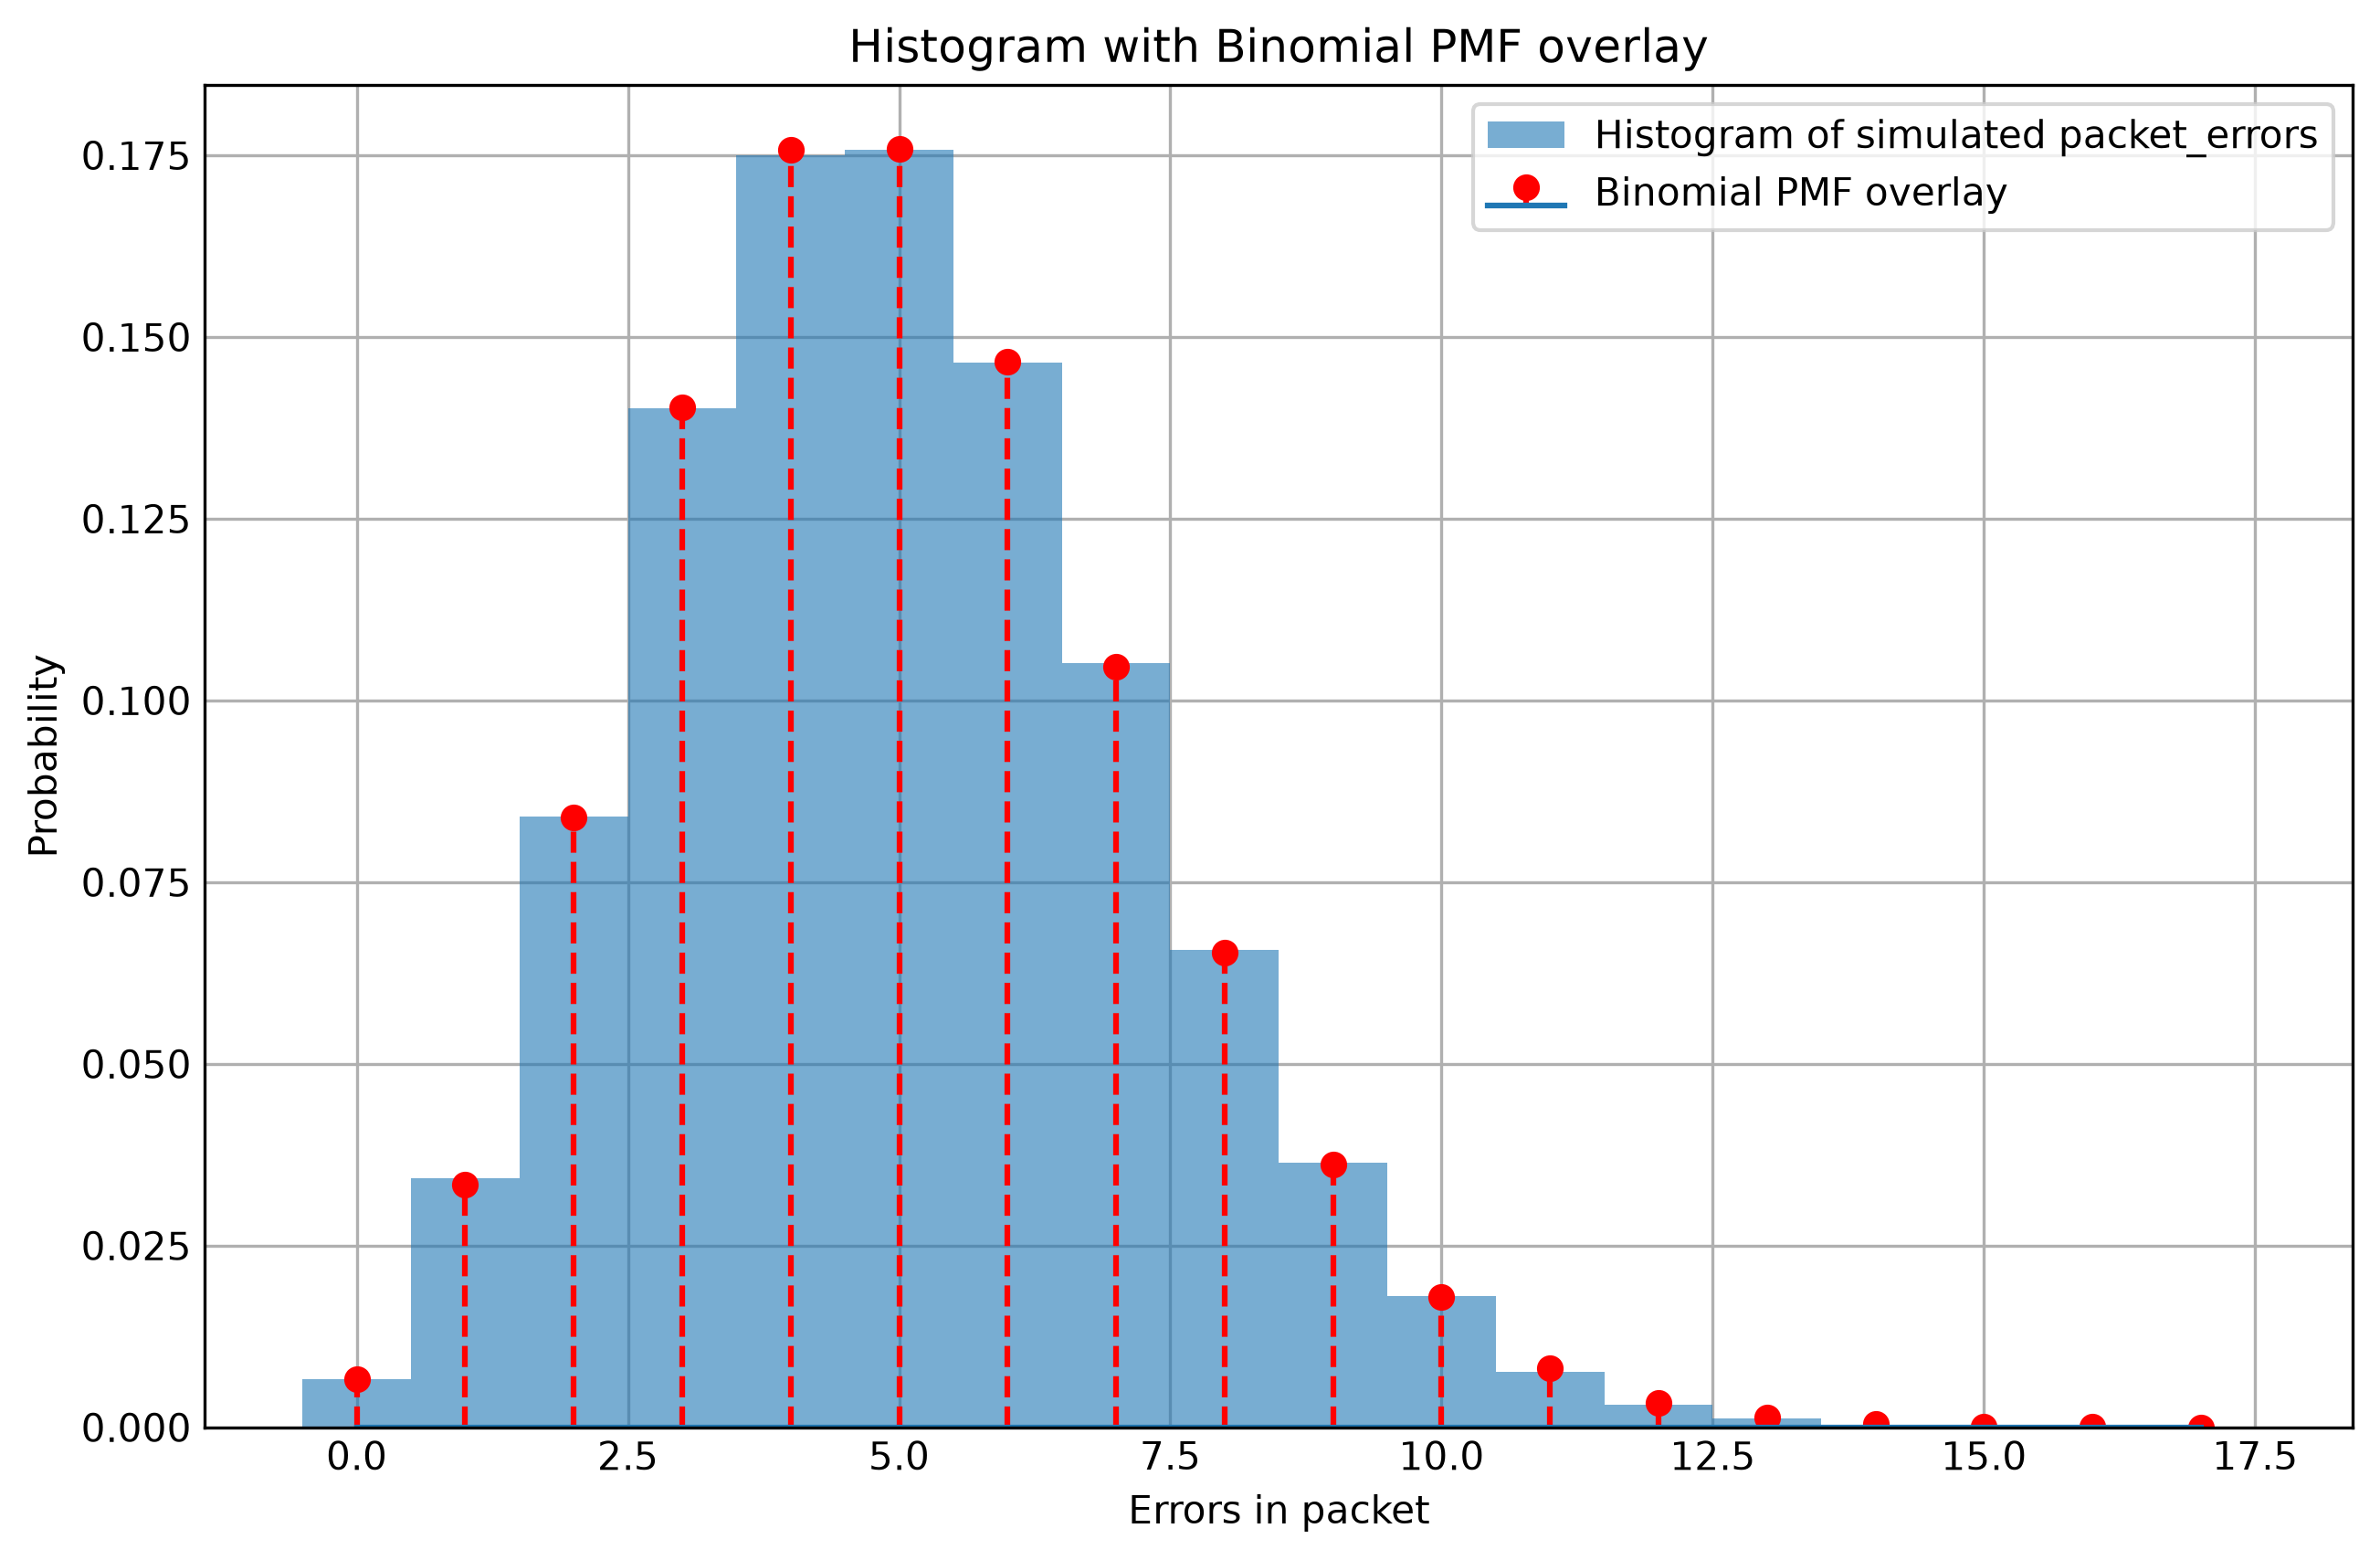

In [124]:
# Question 2: For p = 0.005, simulate 10^5 packets with packet_errors and histogram the error
# count as a density. Overlay the exact Binomial pmf.
p = 0.005
n_pkts = 10**5
n_bits = 1000
fig_4, ax_4 = plt.subplots(figsize = (8, 5), dpi = 300)
pkt_errs = ml.packet_errors(n_pkts,n_bits,p,rng_4)

# Histogram
bins = np.arange(pkt_errs.max() + 2) - 0.5 # bins of -0.5, 0.5...
# print (bins)
ax_4.hist(pkt_errs, bins = bins, density = True, alpha = 0.6, label = 'Histogram of simulated packet_errors')

# Binomial pmf overlay
x_pmf = np.arange(0, pkt_errs.max() + 1, 1)
y_pmf = binom.pmf(x_pmf, n_bits, p)
ax_4.stem(x_pmf, y_pmf, linefmt = 'r--', label = 'Binomial PMF overlay')

ax_4.set_title(r'Histogram with Binomial PMF overlay')
ax_4.set_xlabel('Errors in packet')
ax_4.set_ylabel('Probability')
ax_4.legend()

### Question 3: 
Compute the sample mean and sample variance of the error count and compare against the closed forms for the Binomial. State both closed forms

$n_{pkts} = 10000, n_{bits} = 1000, p = 0.005$

Theoretical Sample Mean of errors in packet:

$\bar(err) = n_{bits}\cdot p = 5.0$

Theoretical Sample Variance of errors in packet:

$\text{Var}(err) = n_{bits}p(1-p) = 4.975$

n_{bits} n_{pkts}


In [125]:
# Quesiton 3: .

print (f"Simulation Sample Mean:       {(np.sum(pkt_errs) / pkt_errs.shape)[0]}")
print (f"Simulation Sample Variance:   {np.var(pkt_errs, ddof = 1)}")


Simulation Sample Mean:       4.99469
Simulation Sample Variance:   4.95241132801328


In [126]:
# Quesiton 4: Compute the probability that a packet arrives with zero errors, exactly and
# empirically, for p in {0.005, 0.001, 0.0001}. Print the three pairs.

p = [0.005, 0.001, 0.0001]
# print (p)

err_0 = binom.pmf(0, n_bits, p)
print(err_0)

print ("Probability that packet arrives with:")
for i in range(0, 3):
    print (f"p = {p[i]:}:\terr = {err_0[i]:.5f}")

[0.00665397 0.36769542 0.90483289]
Probability that packet arrives with:
p = 0.005:	err = 0.00665
p = 0.001:	err = 0.36770
p = 0.0001:	err = 0.90483


## Step 5: The Poisson approximation

In [128]:
# call rng_5

## Step 6: Retransmissions and the geometric distribution

In [129]:
# call rng_6

## Step 7: Expectation, variance, and how fast estimates settle

In [130]:
# call rng_7

## Step 8: Putting it together, the throughput of the link

In [131]:
# call rng_8